# Generalized additive models: example with wage data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pygam import LinearGAM, s, f

A generalized additive model (GAM) assumes
$$y \sim \text{ExponentialFamily}(\mu \mid X), \qquad g(\mu \mid X) = \beta_0 + f_1(X_1) + f_2(X_2, X_3) + \ldots + f_M(X_N),$$
where the $f_j$ are smooth functions (penalized splines) estimated from the data. In `pygam`:

| Model | Distribution | Link |
|---|---|---|
| `LinearGAM` | normal | identity |
| `LogisticGAM` | binomial | logit |
| `PoissonGAM` | Poisson | log |
| `GammaGAM` | gamma | log |
| `InvGaussGAM` | inverse Gaussian | log |
| `ExpectileGAM` | (expectile regression) | identity |
| `GAM` | base class: `distribution` in `'normal'`, `'binomial'`, `'poisson'`, `'gamma'`, `'inv_gauss'`, and `link` in `'identity'`, `'logit'`, `'inverse'`, `'log'`, `'inverse-squared'` | |

The terms are `s` (spline), `f` (factor), `l` (linear) and `te` (tensor product of several variables).

## The data

Wages of 3000 male workers of the Mid-Atlantic region of the United States (data `Wage` of James, Witten, Hastie & Tibshirani, An Introduction to Statistical Learning). We explain the wage (in thousands of dollars per year) with the year, the age and the education level.

In [2]:
dat = pd.read_csv('wage.csv', index_col=0)
dat['education'] = dat['education'].astype('category')
education_levels = [level.split('. ')[1] for level in dat['education'].cat.categories]

X = np.column_stack([dat['year'], dat['age'], dat['education'].cat.codes]).astype(float)
y = dat['wage'].to_numpy()

titles = ['year', 'age', 'education']
print('Education levels:', dict(enumerate(education_levels)))
X

Education levels: {0: '< HS Grad', 1: 'HS Grad', 2: 'Some College', 3: 'College Grad', 4: 'Advanced Degree'}


array([[2.006e+03, 1.800e+01, 0.000e+00],
       [2.004e+03, 2.400e+01, 3.000e+00],
       [2.003e+03, 4.500e+01, 2.000e+00],
       ...,
       [2.005e+03, 2.700e+01, 0.000e+00],
       [2.005e+03, 2.700e+01, 2.000e+00],
       [2.009e+03, 5.500e+01, 1.000e+00]], shape=(3000, 3))

In [3]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
ci_color    = '#7fb8d8'

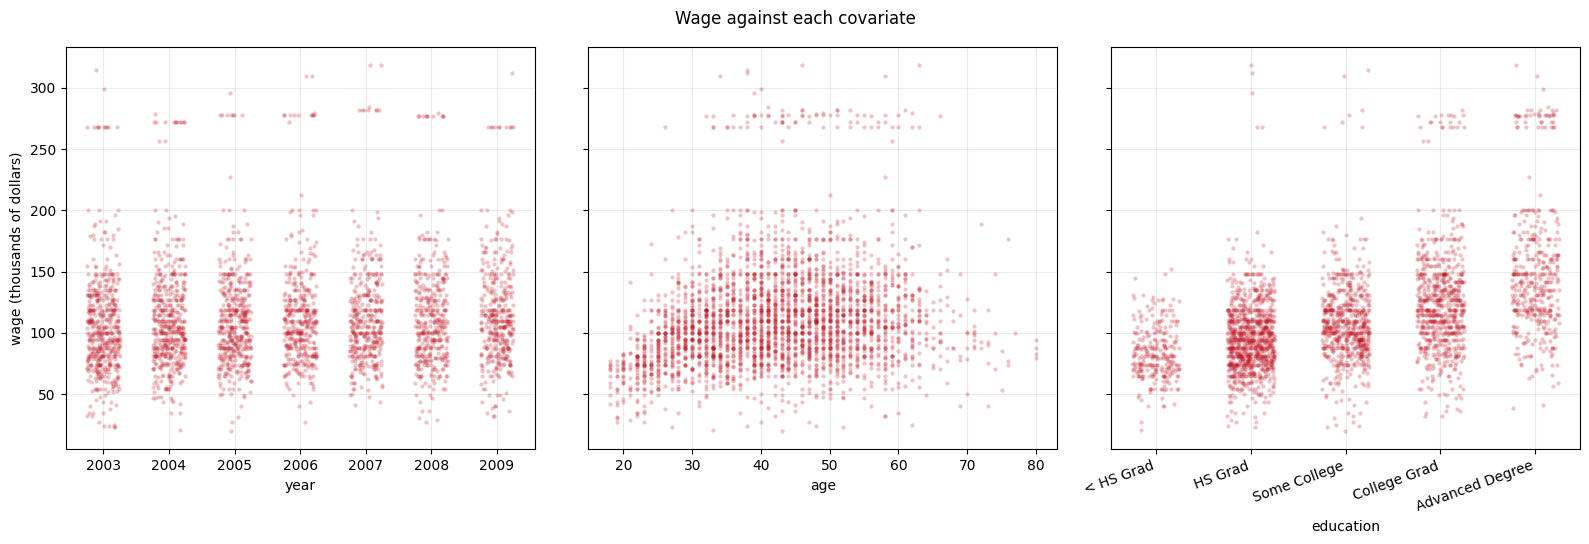

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
rng = np.random.default_rng(0)
for i, ax in enumerate(axes):
    jitter = rng.uniform(-0.25, 0.25, len(y)) if i != 1 else 0
    ax.plot(X[:, i] + jitter, y, 'o', color=point_color, markersize=3, alpha=0.25, markeredgewidth=0)
    ax.set_xlabel(titles[i])
    ax.grid(True, alpha=0.25)
axes[2].set_xticks(range(5), education_levels, rotation=20, ha='right')
axes[0].set_ylabel('wage (thousands of dollars)')
fig.suptitle('Wage against each covariate')
plt.tight_layout()

## A first model

Splines for the year and the age, and a factor for the education. `gridsearch` chooses the penalty of the smooth terms by generalized cross-validation.

In [5]:
gam1 = LinearGAM(s(0) + s(1) + f(2), fit_intercept=False)
gam1.gridsearch(X, y, progress=False)

print('Effective degrees of freedom:', gam1.statistics_['edof'])
print('GCV:                         ', gam1.statistics_['GCV'])

Effective degrees of freedom: 19.260229414956953
GCV:                          1250.3655765924382


In [6]:
def plot_gam(gam, title):
    # Partial dependence of each term, with its 95% confidence interval
    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
    for i, ax in enumerate(axes):
        XX = gam.generate_X_grid(term=i)
        pdep, confi = gam.partial_dependence(term=i, X=XX, width=.95)
        if i < 2:
            ax.fill_between(XX[:, i], confi[:, 0], confi[:, 1], color=ci_color, alpha=0.7, label='95% confidence interval')
            ax.plot(XX[:, i], pdep, color=line_color, lw=2, label='Partial dependence')
            # Where the data are
            ax.plot(X[:, i], np.full(len(X), ax.get_ylim()[0]), '|', color=point_color, markersize=8, alpha=0.1)
        else:
            # The factor has one value for each level
            levels = np.arange(5)
            idx = [np.argmin(np.abs(XX[:, i]-level)) for level in levels]
            ax.vlines(levels, confi[idx, 0], confi[idx, 1], color=ci_color, lw=5, label='95% confidence interval')
            ax.plot(levels, pdep[idx], 'o', color=line_color, markersize=9, markeredgecolor='white', markeredgewidth=1,
                    label='Partial dependence')
            ax.set_xticks(levels, education_levels, rotation=20, ha='right')
        ax.set_title(titles[i])
        ax.grid(True, alpha=0.25)
    axes[0].set_ylabel('Contribution to the wage')
    axes[0].legend(loc='upper left', frameon=False)
    fig.suptitle(title)
    plt.tight_layout()

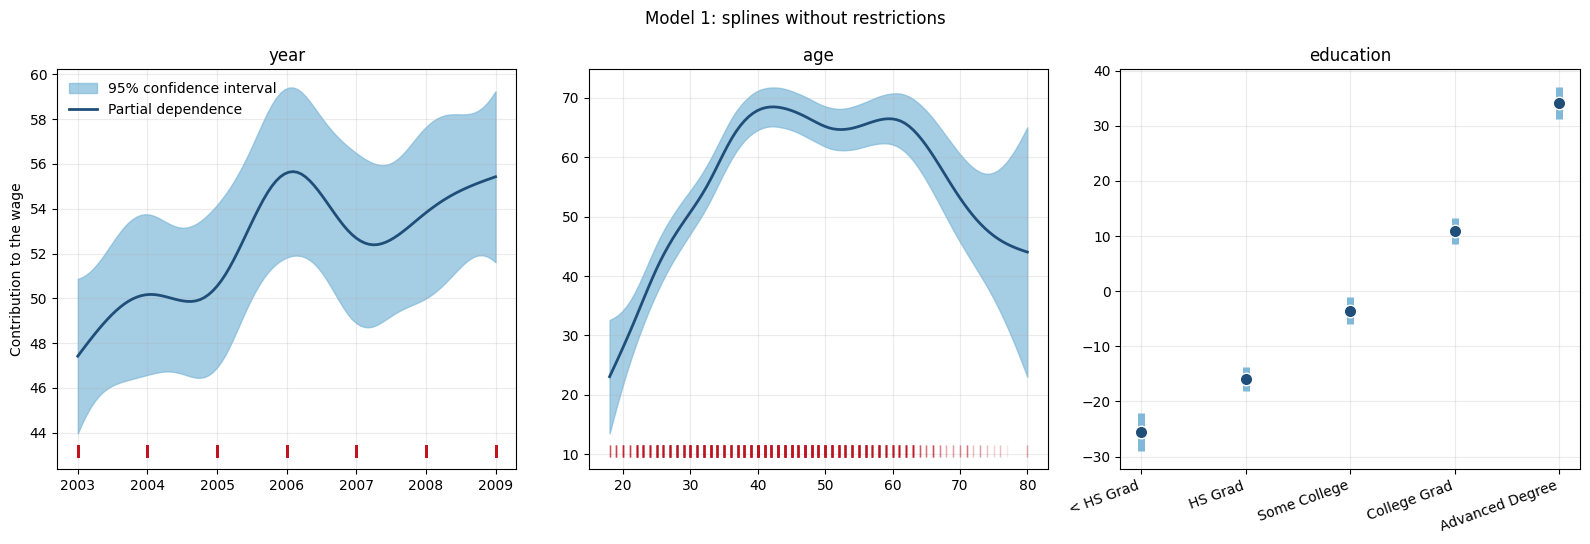

In [7]:
plot_gam(gam1, 'Model 1: splines without restrictions')

### Predictions

The model is additive: the prediction is the sum of the contributions of each term.

In [8]:
def explain_prediction(gam, XX):
    prediction = gam.predict(XX)[0]
    parts = [gam.partial_dependence(term=i, X=XX)[0] for i in range(3)]
    print('Prediction:', prediction)
    for name, part in zip(titles, parts):
        print(f'  contribution of {name}: {part}')
    return prediction, parts

In [9]:
XX = np.array([[2022, 23, 3]])
prediction, parts = explain_prediction(gam1, XX)

Prediction: 116.40875844306186
  contribution of year: 69.50790121207683
  contribution of age: 36.01816584815591
  contribution of education: 10.88269138282913


## Shape restrictions

The estimated effect of the year is not monotone, and the effect of the age wiggles. We can use what we know about the problem and restrict the shape of the splines: the wage should not decrease with the year, and the effect of the age should be concave.

In [10]:
gam2 = LinearGAM(s(0, constraints='monotonic_inc') + s(1, constraints='concave') + f(2), fit_intercept=False)
gam2.gridsearch(X, y, progress=False)

print('Effective degrees of freedom:', gam2.statistics_['edof'])
print('GCV:                         ', gam2.statistics_['GCV'])

Effective degrees of freedom: 13.414795007898254
GCV:                          1245.6519432566245


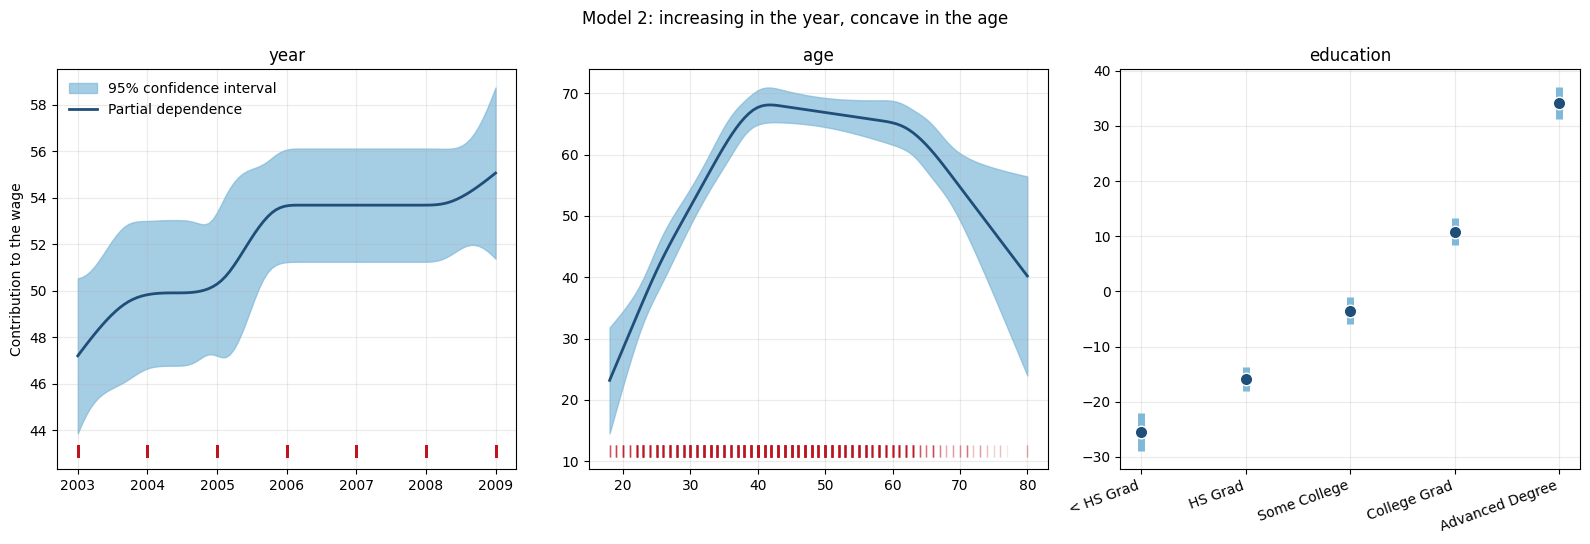

In [11]:
plot_gam(gam2, 'Model 2: increasing in the year, concave in the age')

In [12]:
XX = np.array([[2020, 28, 4]])
prediction, parts = explain_prediction(gam2, XX)

Prediction: 163.12842841961466
  contribution of year: 81.46595439081227
  contribution of age: 47.528924756729246
  contribution of education: 34.13354927207314


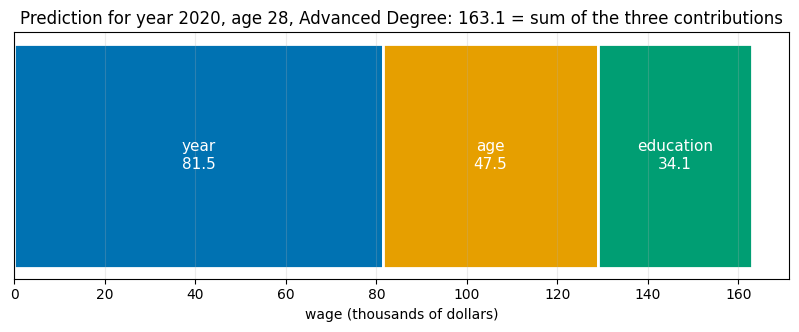

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.2))
left = 0
for name, part, color in zip(titles, parts, ['#0072B2', '#E69F00', '#009E73']):
    ax.barh(0, part, left=left, color=color, edgecolor='white', linewidth=2, height=0.5)
    ax.text(left + part/2, 0, f'{name}\n{part:.1f}', ha='center', va='center', color='white', fontsize=11)
    left += part
ax.set_yticks([])
ax.set_xlabel('wage (thousands of dollars)')
ax.set_title(f'Prediction for year 2020, age 28, {education_levels[4]}: {prediction:.1f} = sum of the three contributions')
ax.grid(True, axis='x', alpha=0.25)

A third model, with only the restriction on the age

In [14]:
gam3 = LinearGAM(s(0) + s(1, constraints='concave') + f(2), fit_intercept=False)
gam3.gridsearch(X, y, progress=False)

print('Effective degrees of freedom:', gam3.statistics_['edof'])
print('GCV:                         ', gam3.statistics_['GCV'])

Effective degrees of freedom: 15.632783687943341
GCV:                          1247.5619769089146


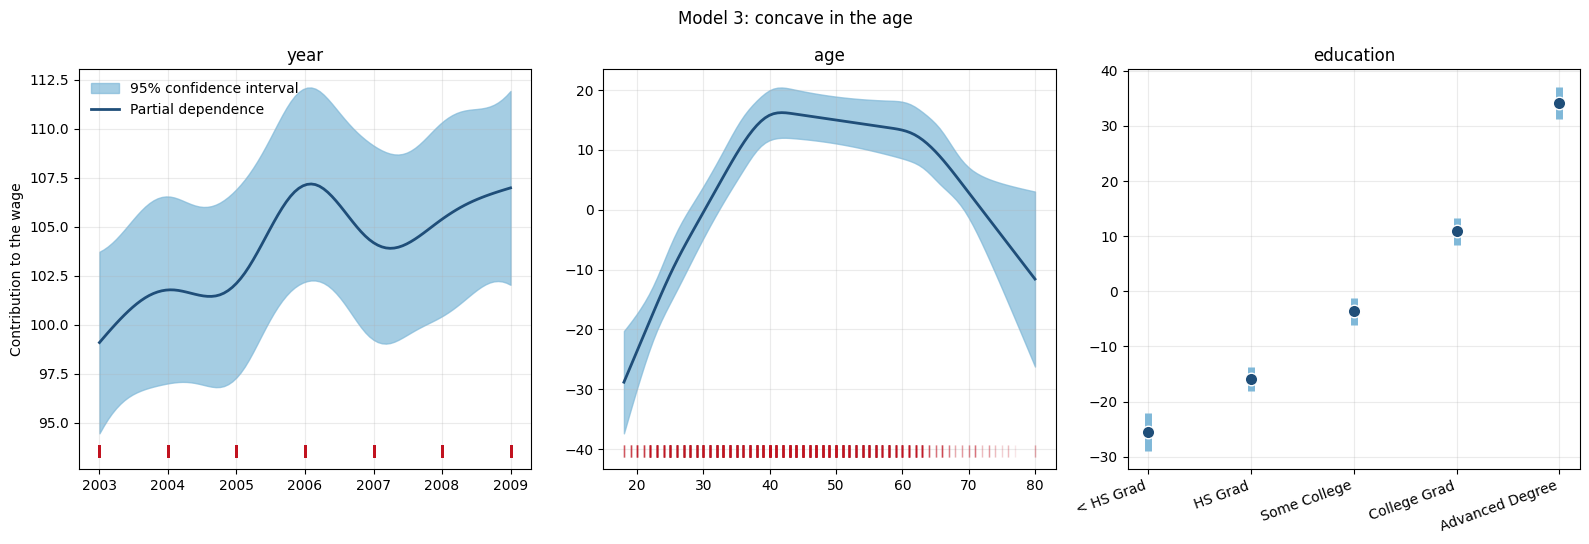

In [15]:
plot_gam(gam3, 'Model 3: concave in the age')

## Comparing the three models

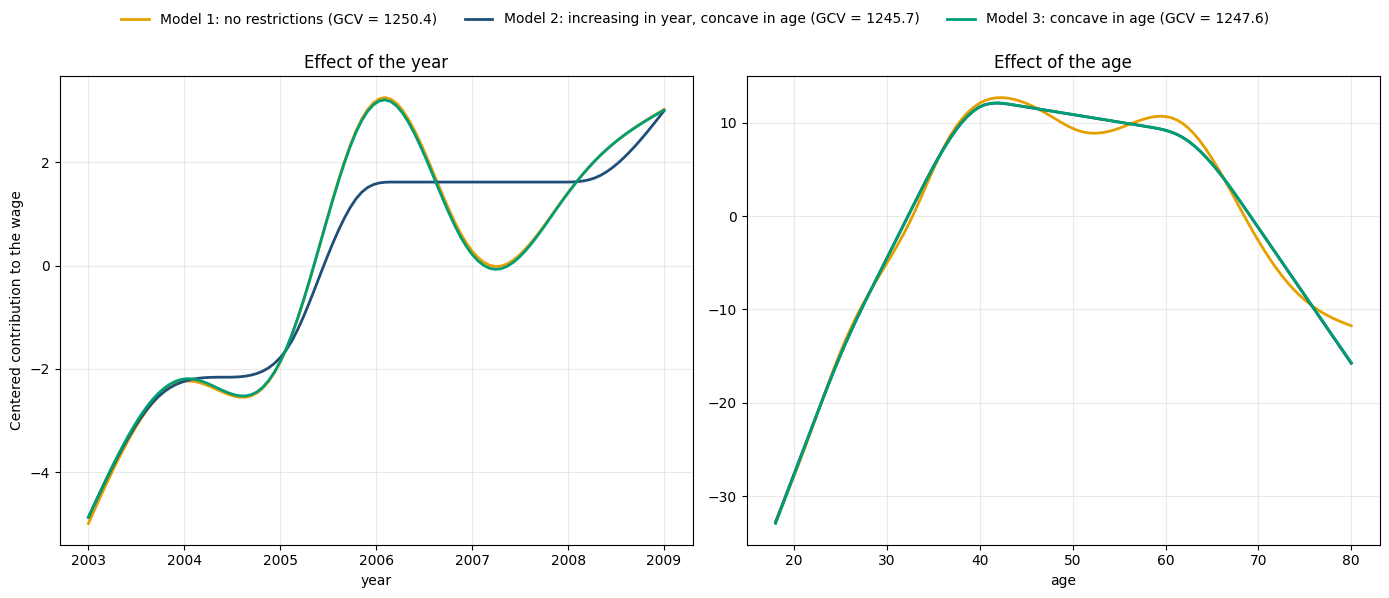

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
models = [(gam1, 'Model 1: no restrictions', '#E69F00'),
          (gam2, 'Model 2: increasing in year, concave in age', line_color),
          (gam3, 'Model 3: concave in age', '#009E73')]
for i, ax in enumerate(axes):
    for gam, name, color in models:
        XX = gam.generate_X_grid(term=i)
        pdep = gam.partial_dependence(term=i, X=XX)
        # Centered, to compare the shapes
        ax.plot(XX[:, i], pdep - pdep.mean(), color=color, lw=2, label=f'{name} (GCV = {gam.statistics_["GCV"]:.1f})')
    ax.set_xlabel(titles[i])
    ax.set_title(f'Effect of the {titles[i]}')
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Centered contribution to the wage')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))